# DWCS/UFC Ascent: can a fight record predict a UFC call-up?
**172 regional MMA fighters from 2024–25 cards, every record hand-verified, and a machine-learning model compared with a hand-built scouting score.**

- **Data:** fighters from LFA, Cage Warriors, Fury FC, UAE Warriors, Brave CF and OKTAGON cards (2024–25). Records were checked bout-by-bout against Sherdog, with Tapology and official sources used to settle conflicts.
- **No future data leaks in:** every stat is taken *before* the fighter's listed regional bout.
- **Label:** `signed = 1` if their first DWCS / UFC / TUF / Road to UFC appearance came after that bout (through 31 Oct 2026). 54 of 172 (31%).
- **Compared:** a 3-line rule of thumb, the hand-built **DWCS/UFC Ascent score**, and a **logistic-regression** model.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

BLUE, ORANGE, GRAY, INK, MUTED, SURF = '#2a78d6', '#eb6834', '#b4b2a9', '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor':SURF,'axes.facecolor':SURF,'axes.edgecolor':GRAY,'axes.labelcolor':MUTED,
    'xtick.color':MUTED,'ytick.color':MUTED,'text.color':INK,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

df = pd.read_csv('dwcs_prospects_172.csv')
df['fights'] = df.wins + df.losses + df.draws
df['win_pct'] = np.where(df.fights > 0, df.wins / df.fights * 100, np.nan)
df['undefeated'] = (df.losses == 0).astype(int)
FEATS = ['wins','losses','fights','win_pct','undefeated','finish_rate','win_streak','title_win','age']
X, y = df[FEATS], df.signed
print(len(df), 'fighters,', y.sum(), 'signed')

172 fighters, 54 signed


## 1. Out-of-fold predictions
Every fighter is scored by a model that never saw them (5-fold cross-validation, repeated 20 times and averaged).

In [2]:
model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, max_iter=1000))
probs = np.mean([cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method='predict_proba')[:,1]
                 for s in range(20)], axis=0)
df['model_prob'] = probs
df['rule'] = df.undefeated + (df.age <= 27).astype(int) + (df.finish_rate >= 60).astype(int)

def boot_auc(score, n=2000, seed=0):
    rng = np.random.default_rng(seed); s = np.asarray(score); yy = y.values; out = []
    for _ in range(n):
        i = rng.integers(0, len(yy), len(yy))
        if yy[i].min() != yy[i].max(): out.append(roc_auc_score(yy[i], s[i]))
    return roc_auc_score(yy, s), *np.percentile(out, [2.5, 97.5])
res = {name: boot_auc(df[col]) for name, col in [('Rule of thumb','rule'),('Ascent score (hand-built)','ascent_score'),('ML model (learned)','model_prob')]}
pd.DataFrame(res, index=['AUC','95% low','95% high']).T.round(3)

,AUC,95% low,95% high
Rule of thumb,0.668,0.584,0.750
Ascent score (hand-built),0.680,0.595,0.762
ML model (learned),0.703,0.623,0.780


## 2. Chart: how the three approaches compare

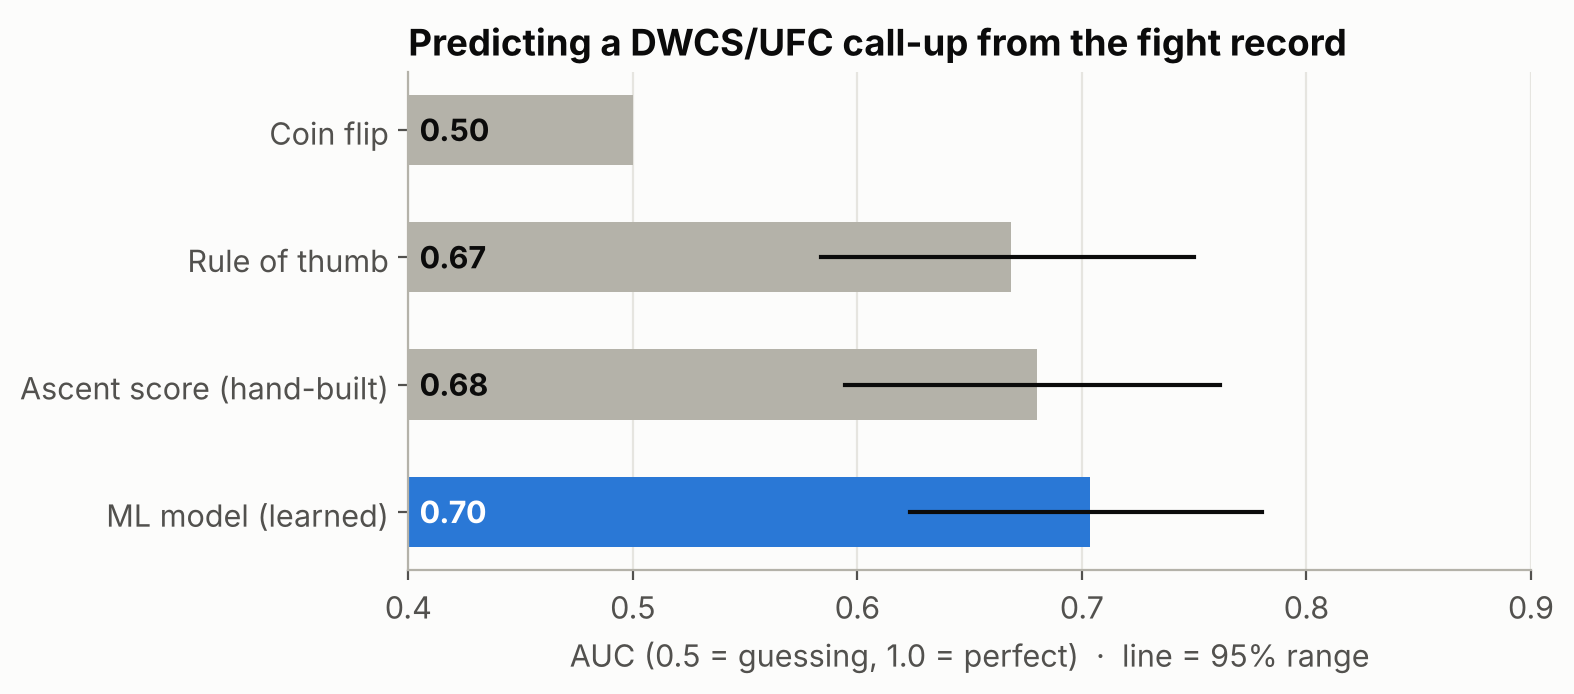

In [3]:
names = ['Coin flip'] + list(res); aucs = [0.5] + [v[0] for v in res.values()]
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = [GRAY, GRAY, GRAY, BLUE]
ax.barh(names, aucs, color=cols, height=0.55)
for i, (n, a) in enumerate(zip(names, aucs)):
    if n in res: ax.plot([res[n][1], res[n][2]], [i, i], color=INK, lw=1.5)
    ax.text(0.405, i, f'{a:.2f}', va='center', ha='left', color='white' if i == 3 else INK, fontweight='bold')
ax.set_xlim(0.4, 0.9); ax.invert_yaxis(); ax.set_xlabel('AUC (0.5 = guessing, 1.0 = perfect)  ·  line = 95% range')
ax.set_title('Predicting a DWCS/UFC call-up from the fight record', loc='left', fontweight='bold')
ax.grid(axis='x', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('charts/1_auc_comparison.png', dpi=200); plt.show()

## 3. Chart: do the model's top picks actually get signed?

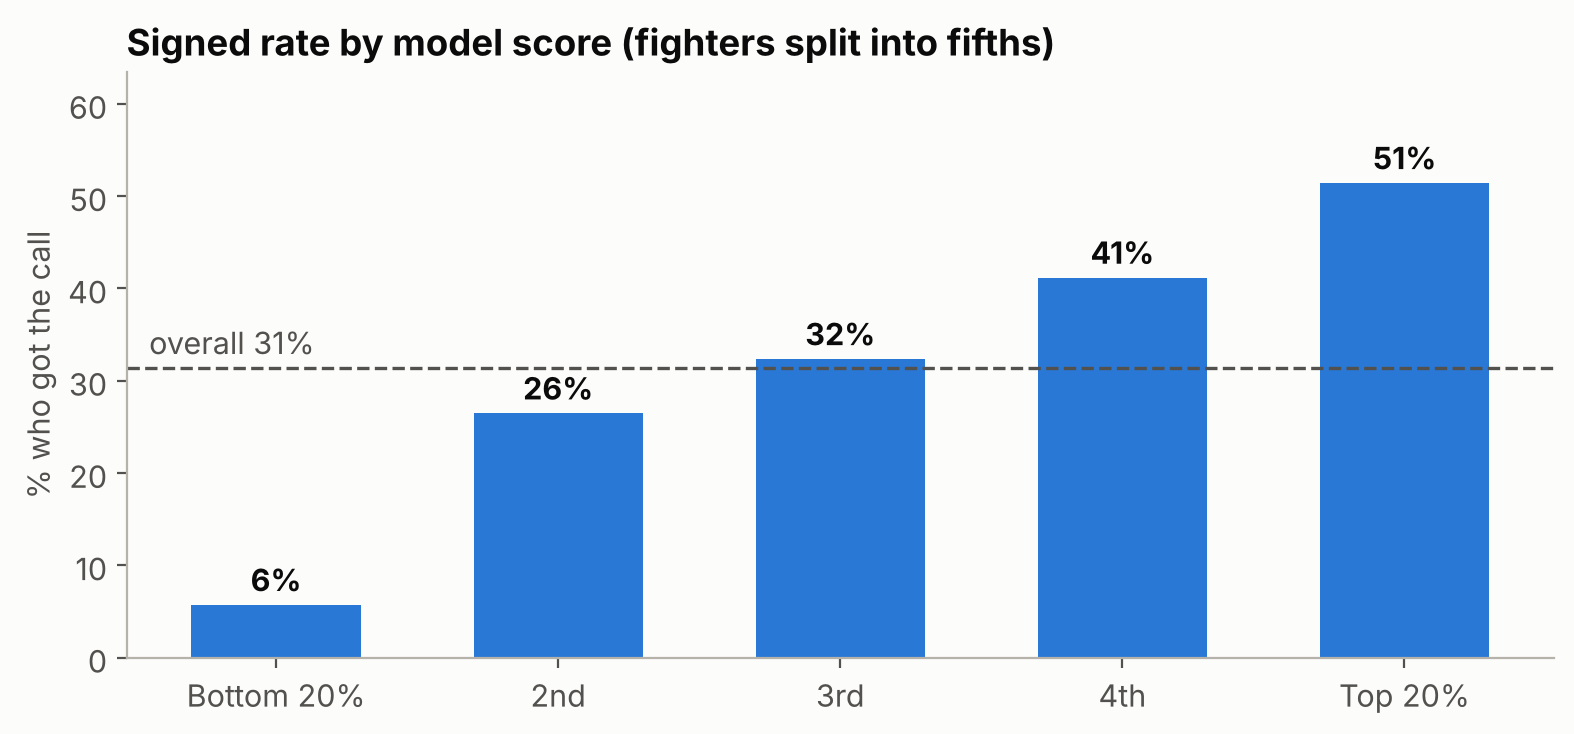

bucket
Bottom 20%     6.0
2nd           26.0
3rd           32.0
4th           41.0
Top 20%       51.0
Name: signed, dtype: float64

In [4]:
df['bucket'] = pd.qcut(df.model_prob.rank(method='first'), 5, labels=['Bottom 20%','2nd','3rd','4th','Top 20%'])
rate = df.groupby('bucket', observed=True).signed.mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
ax.axhline(y.mean()*100, color=MUTED, ls='--', lw=1.2)
ax.text(-0.45, y.mean()*100 + 1.5, f'overall {y.mean()*100:.0f}%', ha='left', color=MUTED)
for i, v in enumerate(rate.values): ax.text(i, v + 1.5, f'{v:.0f}%', ha='center', fontweight='bold')
ax.set_ylabel('% who got the call'); ax.set_ylim(0, max(rate.values) + 12)
ax.set_title('Signed rate by model score (fighters split into fifths)', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/2_signed_rate_by_score.png', dpi=200); plt.show()
rate.round(0)

## 4. Chart: what the model learned to value
Standardised logistic-regression weights (fit on all rows). Blue pushes toward *signed*, orange away. Read the direction; with 172 rows the exact sizes are noisy.

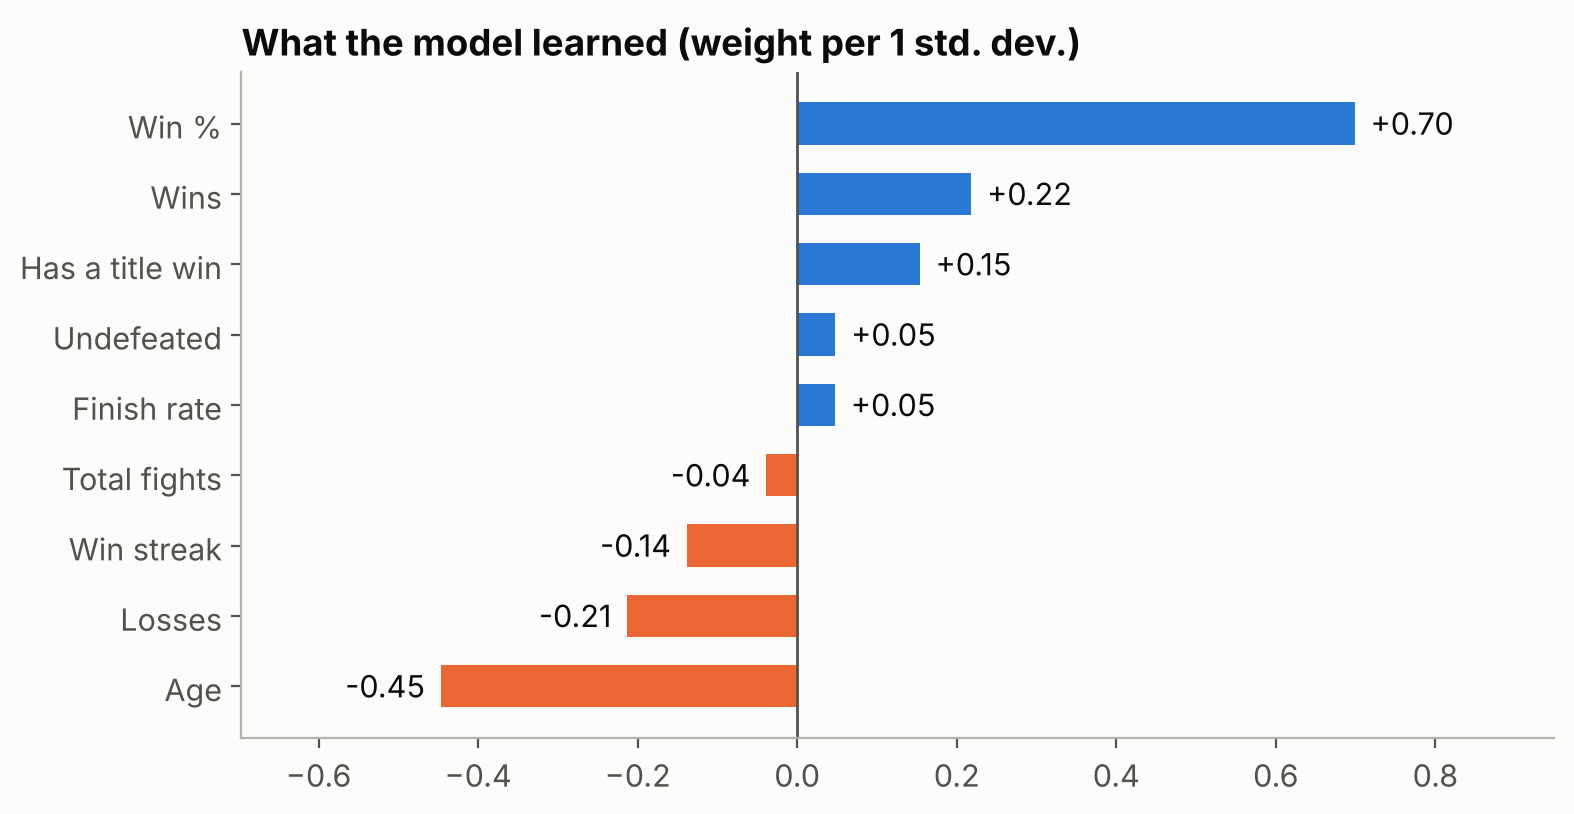

age           -0.45
losses        -0.21
win_streak    -0.14
fights        -0.04
finish_rate    0.05
undefeated     0.05
title_win      0.15
wins           0.22
win_pct        0.70
dtype: float64

In [5]:
model.fit(X, y)
coef = pd.Series(model[-1].coef_[0], index=FEATS).sort_values()
labels = {'wins':'Wins','losses':'Losses','fights':'Total fights','win_pct':'Win %','undefeated':'Undefeated',
          'finish_rate':'Finish rate','win_streak':'Win streak','title_win':'Has a title win','age':'Age'}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([labels[i] for i in coef.index], coef.values, color=[BLUE if v > 0 else ORANGE for v in coef.values], height=0.6)
ax.axvline(0, color=MUTED, lw=1)
for i, v in enumerate(coef.values): ax.text(v + (0.02 if v >= 0 else -0.02), i, f'{v:+.2f}', va='center', ha='left' if v >= 0 else 'right', color=INK)
ax.set_xlim(coef.min() - 0.25, coef.max() + 0.25)
ax.set_title('What the model learned (weight per 1 std. dev.)', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/3_model_weights.png', dpi=200); plt.show()
coef.round(2)

## 5. Learned model vs hand-built Ascent score
Do they rank fighters the same way, and where do they disagree?

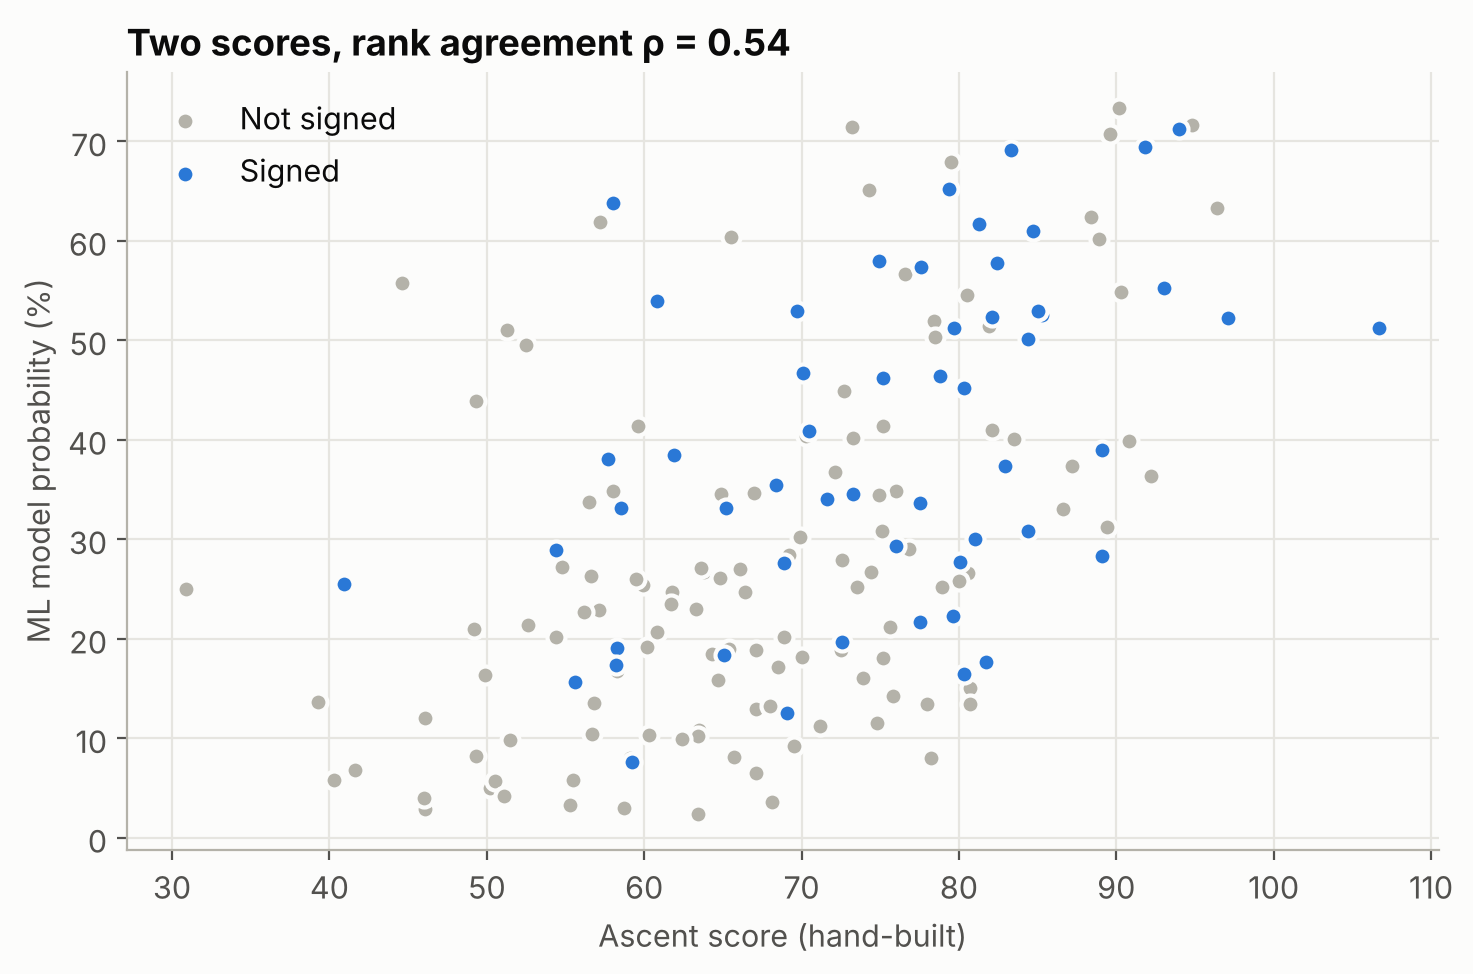

Top-30 overlap: 15 fighters
Signed in model top-30: 15  |  in Ascent top-30: 16  |  expected by chance: 9.4

Model likes more than Ascent:
          fighter    promotion  wins  losses  finish_rate  age  ascent_score  model_prob  signed
    Shadi Kabbani UAE Warriors     3       0          0.0  NaN          44.6        0.56       0
   George Staines           CW     4       0         25.0 24.0          58.0        0.64       1
Mateusz Legierski      OKTAGON    12       2         58.3 29.0          57.2        0.62       0
Alperen Karabulut     Brave CF    11       4         63.6 19.0          51.3        0.51       0
       Lany Silva UAE Warriors     7       2         42.9 23.0          49.3        0.44       0

Ascent likes more than model:
           fighter promotion  wins  losses  finish_rate  age  ascent_score  model_prob  signed
    Dominico Salas        CW     2       1        100.0 36.0          78.2        0.08       0
     Mateus Santos       LFA    18       9         94.4 30

In [6]:
rho = spearmanr(df.ascent_score, df.model_prob).correlation
fig, ax = plt.subplots(figsize=(7.5, 5))
for s, c, lab in [(0, GRAY, 'Not signed'), (1, BLUE, 'Signed')]:
    d = df[df.signed == s]
    ax.scatter(d.ascent_score, d.model_prob*100, s=42, color=c, edgecolor=SURF, linewidth=1.5, label=lab, zorder=3 if s else 2)
ax.set_xlabel('Ascent score (hand-built)'); ax.set_ylabel('ML model probability (%)')
ax.set_title(f'Two scores, rank agreement ρ = {rho:.2f}', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='upper left'); ax.grid(color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('charts/4_ascent_vs_model.png', dpi=200); plt.show()
k = 30
top_m, top_a = set(df.nlargest(k,'model_prob').fighter), set(df.nlargest(k,'ascent_score').fighter)
print(f'Top-{k} overlap: {len(top_m & top_a)} fighters')
print(f'Signed in model top-{k}: {df[df.fighter.isin(top_m)].signed.sum()}  |  in Ascent top-{k}: {df[df.fighter.isin(top_a)].signed.sum()}  |  expected by chance: {y.mean()*k:.1f}')
df['gap'] = df.model_prob.rank(pct=True) - df.ascent_score.rank(pct=True)
cols = ['fighter','promotion','wins','losses','finish_rate','age','ascent_score','model_prob','signed']
print('\nModel likes more than Ascent:'); print(df.nlargest(5,'gap')[cols].round(2).to_string(index=False))
print('\nAscent likes more than model:'); print(df.nsmallest(5,'gap')[cols].round(2).to_string(index=False))

## 6. Adding an AI-extracted feature: gym / team tier
Each fighter's gym (Sherdog *Association* field) was classified by a language model (Claude) into **elite / established / regional** with a fixed rubric. See `extract_gym_tier.py`; results are cached in `gym_tiers_cache.json`.

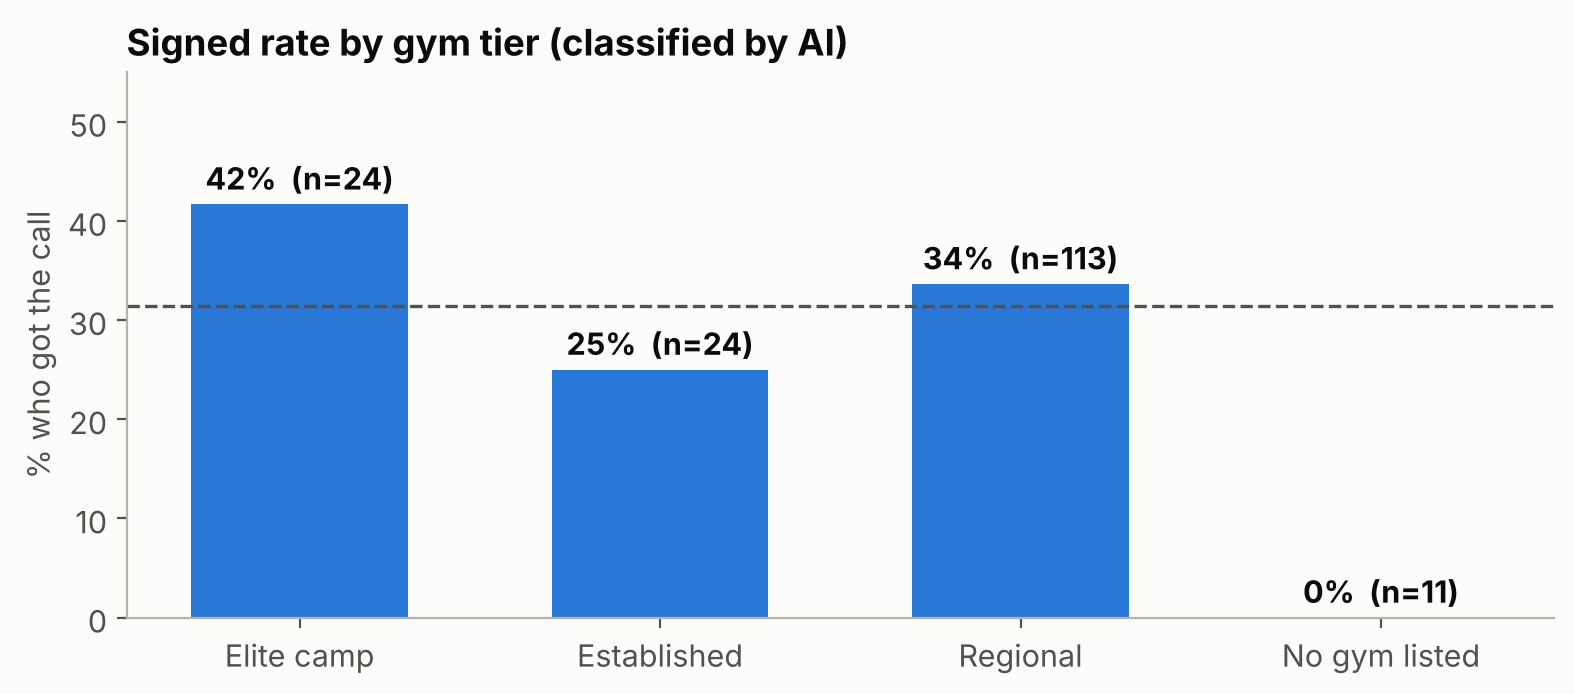

Record only                         0.703
Record + elite gym                  0.696
Record + elite gym + gym listed*    0.720
Name: AUC, dtype: float64

In [7]:
tier_name = df.gym_tier.map({2:'Elite camp', 1:'Established', 0:'Regional'}).fillna('No gym listed')
order = ['Elite camp','Established','Regional','No gym listed']
g = df.groupby(tier_name).signed.agg(['count','mean']).reindex(order)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(order, g['mean']*100, color=[BLUE, BLUE, BLUE, GRAY], width=0.6)
ax.axhline(y.mean()*100, color=MUTED, ls='--', lw=1.2)
for i, (n, v) in enumerate(zip(g['count'], g['mean']*100)): ax.text(i, v + 1.5, f'{v:.0f}%  (n={n})', ha='center', fontweight='bold')
ax.set_ylabel('% who got the call'); ax.set_ylim(0, 55)
ax.set_title('Signed rate by gym tier (classified by AI)', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/5_gym_tier.png', dpi=200); plt.show()

df['elite_gym'] = (df.gym_tier == 2).astype(int); df['gym_listed'] = df.gym_tier.notna().astype(int)
def oof_auc(F):
    p = np.mean([cross_val_predict(model, df[F], y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method='predict_proba')[:,1] for s in range(20)], axis=0)
    return round(roc_auc_score(y, p), 3)
pd.Series({'Record only': oof_auc(FEATS), 'Record + elite gym': oof_auc(FEATS + ['elite_gym']),
           'Record + elite gym + gym listed*': oof_auc(FEATS + ['elite_gym','gym_listed'])}, name='AUC')

**Result: gym tier doesn't help.** Elite-camp fighters were signed a bit more often (42% vs 34%), but once the record is in the model, gym tier adds nothing. *The only lift comes from "gym listed", and that is probably leakage: Sherdog profiles get filled in after a fighter is signed, so a blank field partly reflects the outcome. It is excluded from the headline result. Gym data is also *current*, not as of the snapshot date, so some fighters may have moved camps after signing.

## Limits
- **Small sample:** 172 fighters, 54 signed. The 95% ranges above overlap, so no approach is *proven* better than another.
- **Uneven follow-up time:** fighters from 2024 bouts had about 2 years to get the call, late-2025 ones about 1. Some current 0s will become 1s.
- **Record-only inputs:** opponent quality, management, weight-class needs and market fit drive signings too, and none of them is in here.
- **Ascent score** was designed to benchmark DWCS *invitees*, partly calibrated on DWCS Season 9 rosters (which overlap with some positives here), and uses promotion tier, which the ML model does not see. Weight class wasn't available here, so a global finish-rate average was used. Formula details are not published.
- **Ages:** 20 fighters have no public birth date and are imputed with the median.